# Suivi des prix alimentaires sur les marchés du Congo-Brazzaville
**Devoir : analyse exploratoire, pré-traitement des données et modélisation**
Olivier Jonathan DIPO WANDO L3 Big Data, DIT

**Source :** Programme alimentaire mondial , publié sur HDX (data.humdata.org).
**Ma Variable cible :** `price` (prix en francs CFA).
**Objectif :** comprendre les données, puis les préparer pour qu'un modèle puisse prédire le prix d'un produit selon le lieu et la date.

**Plan :**
- **Partie 1 – Analyse exploratoire** : inspection, analyse univariée, analyse bivariée
- **Partie 2 – Pré-traitement** : colonnes inutiles, texte, doublons, valeurs manquantes, valeurs aberrantes, encodage, séparation et standardisation
- **Partie 3 – Modélisation** : régression linéaire, Random Forest, XGBoost, comparaison avec R², MSE et MAE, graphiques, conclusion

# PARTIE 1 – ANALYSE EXPLORATOIRE

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## 2. Chargement des données

In [2]:
df = pd.read_csv("wfp_food_prices_cog.csv")
print("Dimensions du dataset :", df.shape)

Dimensions du dataset : (6414, 16)


Le dataset contient **6 414 lignes** (relevés de prix) et **16 colonnes**.

In [3]:
df.head()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2011-01-15,Brazzaville,Brazzaville,Mikalou,703,-4.26,15.28,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Retail,XAF,635.0,1.29
1,2011-01-15,Brazzaville,Brazzaville,Mikalou,703,-4.26,15.28,pulses and nuts,Beans (white),66,KG,actual,Retail,XAF,2091.0,4.25
2,2011-01-15,Brazzaville,Brazzaville,Moungali,701,-4.26,15.28,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Retail,XAF,575.0,1.17
3,2011-01-15,Brazzaville,Brazzaville,Moungali,701,-4.26,15.28,pulses and nuts,Beans (white),66,KG,actual,Retail,XAF,1739.0,3.54
4,2011-01-15,Brazzaville,Brazzaville,Ouenzé,702,-4.25,15.28,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Retail,XAF,595.0,1.21


Chaque ligne est un relevé : **le prix d'un produit, dans un marché, un mois donné**. Par exemple, la première ligne indique que le riz coûtait 635 FCFA le kilo au marché Mikalou (Brazzaville) en janvier 2011.

## 3. Inspection

In [4]:
df.info()
print("Valeurs manquantes :", df.isna().sum().sum())
print("Lignes en double   :", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 6414 entries, 0 to 6413
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          6414 non-null   str    
 1   admin1        6414 non-null   str    
 2   admin2        6414 non-null   str    
 3   market        6414 non-null   str    
 4   market_id     6414 non-null   int64  
 5   latitude      6414 non-null   float64
 6   longitude     6414 non-null   float64
 7   category      6414 non-null   str    
 8   commodity     6414 non-null   str    
 9   commodity_id  6414 non-null   int64  
 10  unit          6414 non-null   str    
 11  priceflag     6414 non-null   str    
 12  pricetype     6414 non-null   str    
 13  currency      6414 non-null   str    
 14  price         6414 non-null   float64
 15  usdprice      6414 non-null   float64
dtypes: float64(4), int64(2), str(10)
memory usage: 801.9 KB
Valeurs manquantes : 0
Lignes en double   : 0


#### Observation
- 16 colonnes : 10 en texte (`object`), 4 décimales (`float64`), 2 entières (`int64`).
- 0 valeur manquante, 0 ligne en double.

#### Analyse
- La colonne `date` est stockée en texte : il faudra la convertir.
- Le fichier semble parfait, mais une ligne n'existe que si un prix a été relevé : des mois sans relevé pourraient être **absents** sans apparaître comme vides.

#### Interprétation
Ce premier contrôle ne suffit pas : il faudra vérifier plus finement les valeurs manquantes (partie 2).

In [5]:
df.describe().round(1)

,market_id,latitude,longitude,commodity_id,price,usdprice
count,6414.0,6414.0,6414.0,6414.0,6414.0,6414.0
mean,1681.5,-2.7,15.0,152.5,1374.3,2.4
std,1840.4,3.0,2.2,100.8,1311.3,2.2
min,701.0,-4.8,11.8,55.0,112.0,0.2
25%,705.0,-4.3,13.3,66.0,621.2,1.1
50%,707.0,-4.3,15.3,119.0,940.5,1.6
75%,1821.0,-3.7,15.3,207.0,1572.8,2.8
max,7775.0,3.4,18.6,401.0,23542.0,39.3


#### Observation
- Le prix va de **112** à **23 542 FCFA**, avec une moyenne de 1 374 et une médiane de 940.
- L'écart-type (1 311) est presque aussi grand que la moyenne.

#### Analyse
- La moyenne est bien supérieure à la médiane : quelques prix très élevés tirent la moyenne vers le haut.
- Le maximum (23 542) est très éloigné du 3e quartile (1 573) : valeur suspecte.
- `usdprice` suit exactement `price` (c'est le même prix converti en dollars).

#### Interprétation
Les prix sont très dispersés, ce qui s'explique en partie par le mélange de produits très différents. Le maximum devra être vérifié.

## 4. Analyse univariée : variable numérique (le prix)

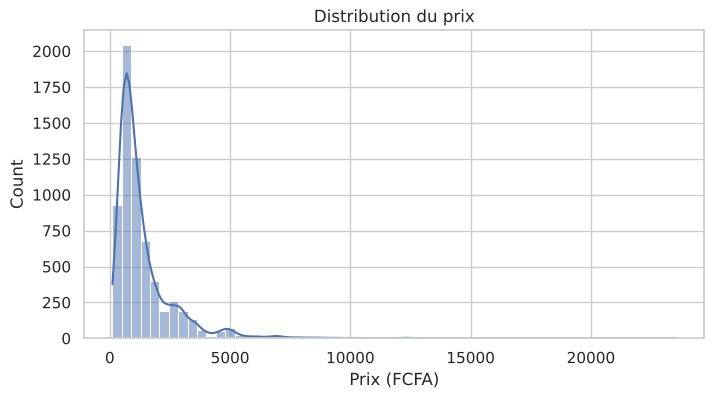

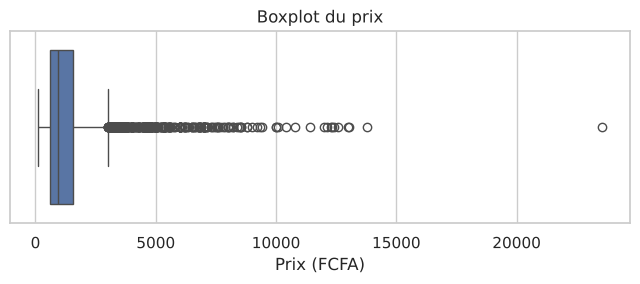

count     6414.0
mean      1374.3
std       1311.3
min        112.0
25%        621.2
50%        940.5
75%       1572.8
max      23542.0
Name: price, dtype: float64
Coefficient d'asymétrie : 3.71


In [6]:
plt.figure(figsize=(8,4))
sns.histplot(df["price"], bins=60, kde=True)
plt.title("Distribution du prix")
plt.xlabel("Prix (FCFA)")
plt.show()

plt.figure(figsize=(8,2.5))
sns.boxplot(x=df["price"])
plt.title("Boxplot du prix")
plt.xlabel("Prix (FCFA)")
plt.show()

print(df["price"].describe().round(1))
print("Coefficient d'asymétrie :", round(df["price"].skew(), 2))

#### Observation
- La plupart des prix sont entre **600 et 1 600 FCFA**.
- Quelques prix sont beaucoup plus élevés, jusqu'à 23 542 FCFA.

#### Analyse
- Distribution **asymétrique à droite** (coefficient d'asymétrie de 3,7) : beaucoup de prix bas, peu de prix très élevés.
- Le boxplot montre de nombreuses valeurs au-delà de la moustache, et un point isolé très loin des autres.

#### Interprétation
Les prix élevés peuvent venir de produits naturellement chers (viande, poisson) ou d'erreurs de saisie. Il faudra distinguer les deux (partie 2, valeurs aberrantes).

## 5. Analyse univariée : variables catégorielles

### Les produits

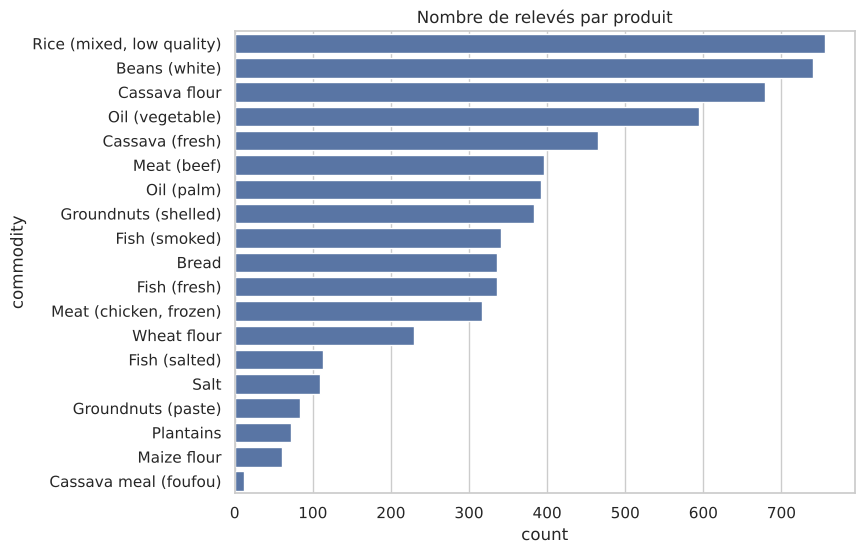

,effectif,fréquence (%)
commodity,,
"Rice (mixed, low quality)",756,11.8
Beans (white),740,11.5
Cassava flour,679,10.6
Oil (vegetable),594,9.3
Cassava (fresh),465,7.2
Meat (beef),396,6.2
Oil (palm),392,6.1
Groundnuts (shelled),383,6.0
Fish (smoked),341,5.3


In [7]:
plt.figure(figsize=(8,6))
sns.countplot(data=df, y="commodity", order=df["commodity"].value_counts().index)
plt.title("Nombre de relevés par produit")
plt.show()

tableau = pd.DataFrame({
    "effectif": df["commodity"].value_counts(),
    "fréquence (%)": (df["commodity"].value_counts(normalize=True) * 100).round(1)
})
tableau

#### Observation
- **19 produits**. Les plus suivis : riz (756 relevés), haricots (740), farine de manioc (679), huile végétale (594).
- Les moins suivis : banane plantain (72), farine de maïs (60), foufou (12).

#### Analyse
Répartition **déséquilibrée** : les 4 premiers produits représentent plus de 40 % des relevés.

#### Interprétation
Le PAM suit en priorité les produits de base. Le modèle apprendra mieux sur ces produits que sur ceux qui ont très peu de relevés, comme le foufou.

### Les départements

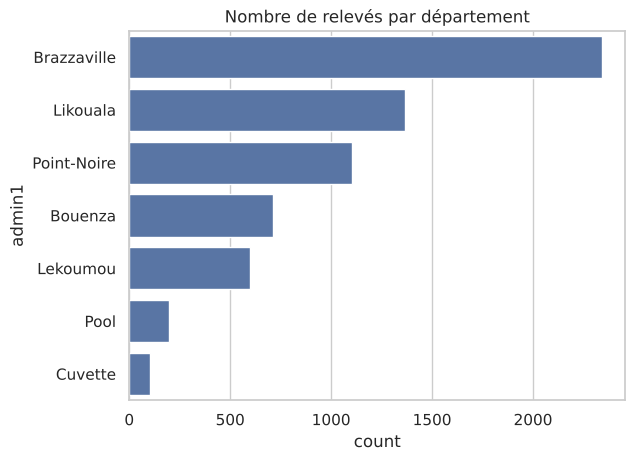

,effectif,fréquence (%)
admin1,,
Brazzaville,2340,36.5
Likouala,1366,21.3
Point-Noire,1102,17.2
Bouenza,710,11.1
Lekoumou,597,9.3
Pool,195,3.0
Cuvette,104,1.6


In [8]:
sns.countplot(data=df, y="admin1", order=df["admin1"].value_counts().index)
plt.title("Nombre de relevés par département")
plt.show()

tableau_1 = pd.DataFrame({
    "effectif": df["admin1"].value_counts(),
    "fréquence (%)": (df["admin1"].value_counts(normalize=True) * 100).round(1)
})
tableau_1

#### Observation
- **7 départements**. Brazzaville concentre **36,5 %** des relevés, la Cuvette seulement **1,6 %**.
- Le département de Pointe-Noire est écrit **« Point-Noire »**.

#### Analyse
- Forte **inégalité** de couverture entre départements.
- Une **faute de frappe** dans les noms.

#### Interprétation
- Le modèle connaîtra mieux les prix de Brazzaville que ceux de la Cuvette ou du Pool.
- La faute devra être corrigée (partie 2).

### Les unités

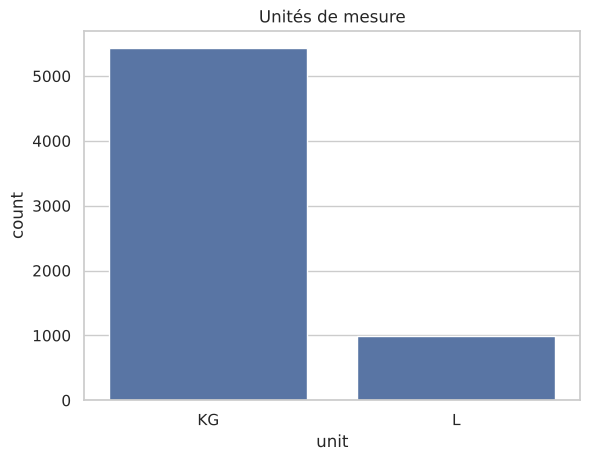

,effectif,fréquence (%)
unit,,
KG,5428,84.6
L,986,15.4


In [9]:
sns.countplot(data=df, x="unit")
plt.title("Unités de mesure")
plt.show()

tableau_2 = pd.DataFrame({
    "effectif": df["unit"].value_counts(),
    "fréquence (%)": (df["unit"].value_counts(normalize=True) * 100).round(1)
})
tableau_2

#### Observation
- **84,6 %** des prix sont au kilo (KG), **15,4 %** au litre (L).

#### Analyse
Le litre concerne uniquement les huiles (végétale et de palme).

#### Interprétation
Les prix au kilo et au litre ne se comparent pas directement : l'unité doit rester une variable du modèle.

### Le nombre de relevés par année

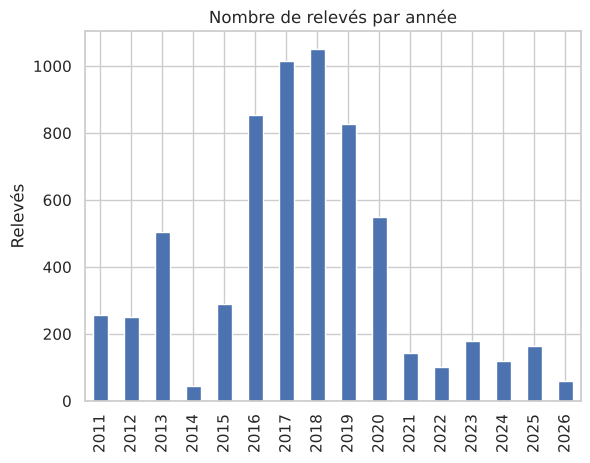

In [10]:
df["annee"] = pd.to_datetime(df["date"]).dt.year
df["annee"].value_counts().sort_index().plot(kind="bar")
plt.title("Nombre de relevés par année")
plt.ylabel("Relevés")
plt.xlabel("")
plt.show()

#### Observation
- Pic de relevés entre **2016 et 2019** (plus de 800 par an).
- Très peu de relevés en **2014** (44) et après **2021** (60 à 180 par an).

#### Analyse
La collecte est très **irrégulière** dans le temps.

#### Interprétation
Certaines années sont peu représentées : il y a probablement des mois sans relevé, à vérifier dans la partie 2. Le peu de données après 2021 rendra le jeu de test petit.

## 6. Analyse bivariée : le prix selon les autres variables

### Prix selon le produit

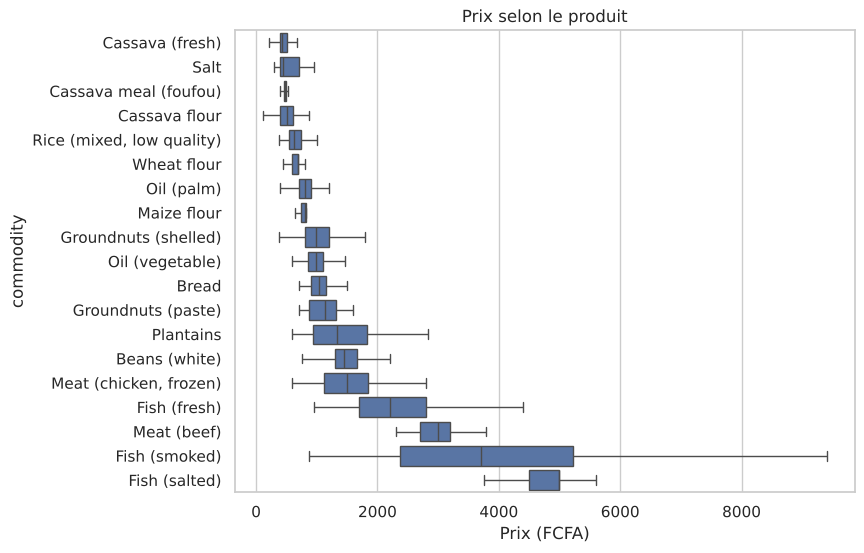

In [11]:
ordre = df.groupby("commodity")["price"].median().sort_values().index
plt.figure(figsize=(8,6))
sns.boxplot(data=df, y="commodity", x="price", order=ordre, showfliers=False)
plt.title("Prix selon le produit")
plt.xlabel("Prix (FCFA)")
plt.show()

#### Observation
- Prix médian le plus bas : **manioc frais** (432 FCFA/kg) ; le plus élevé : **poisson salé** (5 000 FCFA/kg).
- Les poissons et la viande sont nettement plus chers que les céréales et le manioc.

#### Analyse
Le prix dépend **très fortement** du produit : jusqu'à plus de 10 fois d'écart.

#### Interprétation
Le **produit** est la variable la plus importante pour prédire le prix. Cela explique aussi l'asymétrie observée à l'étape 4 : les prix élevés sont surtout ceux des produits chers.

### Prix du riz selon le département

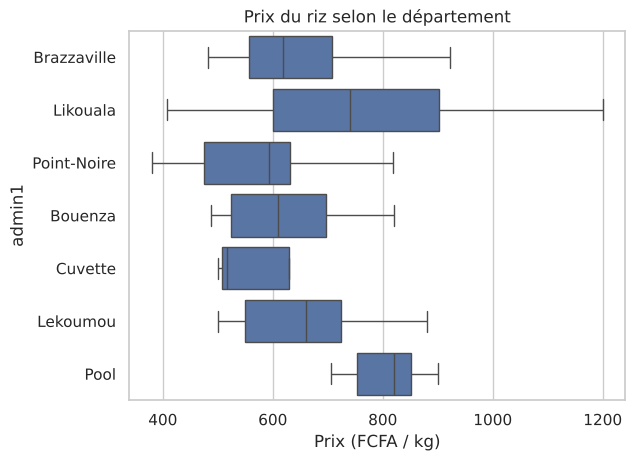

admin1
Bouenza        609.0
Brazzaville    619.0
Cuvette        516.5
Lekoumou       660.0
Likouala       740.0
Point-Noire    594.0
Pool           820.0
Name: price, dtype: float64

In [12]:
riz = df[df["commodity"] == "Rice (mixed, low quality)"]
sns.boxplot(data=riz, y="admin1", x="price", showfliers=False)
plt.title("Prix du riz selon le département")
plt.xlabel("Prix (FCFA / kg)")
plt.show()

riz.groupby("admin1")["price"].median()

*On compare un seul produit (le riz) pour que les écarts ne viennent pas du mélange de produits.*

#### Observation
- Le prix médian du riz va de **517 FCFA** (Cuvette) à **820 FCFA** (Pool).
- Brazzaville (619) et Point-Noire (594) sont dans la moyenne basse.

#### Analyse
Il existe des **écarts régionaux** pour un même produit.

#### Interprétation
Le **lieu** influence le prix (transport, approvisionnement). Attention : les départements n'ont pas été suivis aux mêmes années, une partie de l'écart peut venir de la période.

### Évolution du prix dans le temps

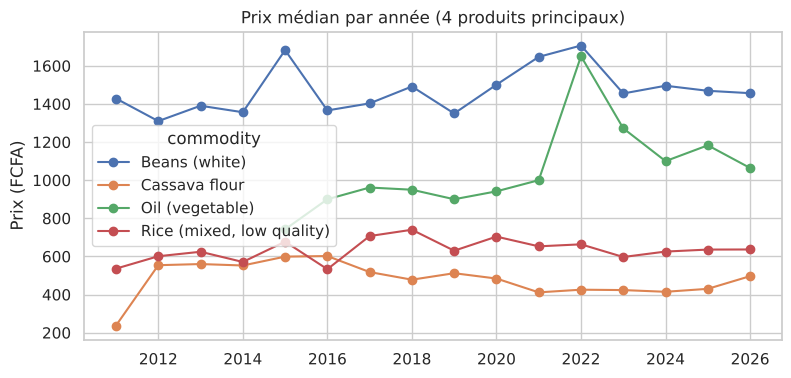

In [13]:
produits = ["Rice (mixed, low quality)", "Cassava flour", "Beans (white)", "Oil (vegetable)"]
evolution = (df[df["commodity"].isin(produits)]
             .groupby(["annee", "commodity"])["price"].median()
             .unstack())
evolution.plot(marker="o", figsize=(9,4))
plt.title("Prix médian par année (4 produits principaux)")
plt.ylabel("Prix (FCFA)")
plt.xlabel("")
plt.show()

#### Observation
- L'**huile végétale** passe d'environ 1 000 FCFA en 2021 à **1 650 FCFA en 2022**, puis redescend vers 1 100.
- Le riz et les haricots restent relativement stables ; la farine de manioc baisse légèrement après 2016.

#### Analyse
Les prix **varient dans le temps**, avec des chocs ponctuels comme celui de l'huile en 2022.

#### Interprétation
La **date** est une variable utile pour le modèle. Comme les données sont temporelles, il faudra entraîner sur le passé et tester sur le futur.

## 7. Bilan de l'analyse exploratoire

**Variables importantes pour prédire le prix :**
- le **produit** (facteur principal) ;
- le **lieu** (écarts régionaux) ;
- la **date** (évolution et chocs de prix).

**Problèmes détectés dans les données :**
- distribution du prix **asymétrique**, avec des **valeurs extrêmes** suspectes ;
- une **faute de frappe** (« Point-Noire ») ;
- une collecte **irrégulière** dans le temps : des valeurs manquantes sont probablement cachées ;
- des variables **déséquilibrées** (Brazzaville, produits de base, unité KG).

Ces constats guident le pré-traitement de la partie 2.

In [14]:
df = df.drop(columns=["annee"])

# PARTIE 2 – PRÉ-TRAITEMENT DES DONNÉES

## 8. Suppression des colonnes inutiles
On compte le nombre de valeurs différentes dans chaque colonne pour repérer celles qui n'apportent rien.

In [15]:
df.nunique().sort_values()

pricetype          1
currency           1
priceflag          1
unit               2
category           6
admin1             7
admin2             8
latitude          10
longitude         10
market            13
market_id         13
commodity         19
commodity_id      19
date             157
usdprice         813
price           1555
dtype: int64

**Observations :**
- `pricetype`, `currency` et `priceflag` n'ont qu'**une seule valeur** : aucune information.
- `market_id` et `commodity_id` répètent `market` et `commodity` (13 et 19 valeurs).
- `category` se déduit du produit.
- `usdprice` est le prix converti en dollars : c'est la cible déguisée. La garder serait une **fuite de données**.

On supprime ces **7 colonnes** et on convertit la date en vraie date.

In [16]:
df = df.drop(columns=["priceflag", "pricetype", "currency",
                      "market_id", "commodity_id", "category", "usdprice"])
df["date"] = pd.to_datetime(df["date"])
print("Colonnes restantes :", list(df.columns))

Colonnes restantes : ['date', 'admin1', 'admin2', 'market', 'latitude', 'longitude', 'commodity', 'unit', 'price']


## 9. Correction des incohérences de texte
On passe en revue les valeurs de toutes les colonnes de texte (la faute « Point-Noire » a été repérée dès l'analyse exploratoire).

In [17]:
for col in ["admin1", "admin2", "market", "commodity", "unit"]:
    print(col, ":", df[col].unique())
    print()

admin1 : <StringArray>
['Brazzaville',    'Likouala', 'Point-Noire',     'Bouenza',     'Cuvette',
    'Lekoumou',        'Pool']
Length: 7, dtype: str

admin2 : <StringArray>
[ 'Brazzaville',        'Betou',     'Impfondo', 'Pointe-Noire',
        'Nkayi',       'Owando',       'Sibiti',      'Kinkala']
Length: 8, dtype: str

market : <StringArray>
[                             'Mikalou',
                             'Moungali',
                               'Ouenzé',
                                'Total',
                             'Monzombo',
                              'Bakandi',
 'Grand marché/Fond Ntié-Ntié/Nkouikou',
                                'Nkayi',
                               'Owando',
                               'Sibiti',
                          'Brazzaville',
                         'Betou Centre',
                              'Kinkala']
Length: 13, dtype: str

commodity : <StringArray>
['Rice (mixed, low quality)',             'Beans (white)',
      

**Observation :** dans `admin1`, « Point-Noire » est mal écrit, alors que `admin2` l'écrit correctement (« Pointe-Noire »). Les autres colonnes ne présentent pas d'incohérence.

In [18]:
df["admin1"] = df["admin1"].replace("Point-Noire", "Pointe-Noire")
print(df["admin1"].unique())

<StringArray>
[ 'Brazzaville',     'Likouala', 'Pointe-Noire',      'Bouenza',
      'Cuvette',     'Lekoumou',         'Pool']
Length: 7, dtype: str


La faute est corrigée : on retrouve bien les 7 départements.

## 10. Vérification des doublons
Un marché ne doit avoir qu'**un seul prix par produit et par mois**.

In [19]:
print("Doublons (date, marché, produit) :",
      df.duplicated(subset=["date", "market", "commodity"]).sum())
df["market"].value_counts()

Doublons (date, marché, produit) : 0


market
Total                                   1195
Grand marché/Fond Ntié-Ntié/Nkouikou    1102
Nkayi                                    710
Monzombo                                 637
Sibiti                                   597
Betou Centre                             451
Brazzaville                              431
Bakandi                                  278
Mikalou                                  238
Moungali                                 238
Ouenzé                                   238
Kinkala                                  195
Owando                                   104
Name: count, dtype: int64

**Observation :** 0 doublon (date, marché, produit) : chaque relevé est unique, on garde toutes les lignes.

## 11. Valeurs manquantes cachées
Le nombre de relevés par année (étape 5) laisse penser que des mois manquent. On vérifie d'abord les mois sans **aucun** relevé dans tout le dataset.

In [20]:
mois_presents = df["date"].dt.to_period("M").unique()
tous_les_mois = pd.period_range(mois_presents.min(), mois_presents.max(), freq="M")
mois_absents = sorted(set(tous_les_mois) - set(mois_presents))

print("Mois attendus :", len(tous_les_mois))
print("Mois présents :", len(mois_presents))
print("Mois sans aucun relevé :", len(mois_absents))
print([str(m) for m in mois_absents])

Mois attendus : 184
Mois présents : 157
Mois sans aucun relevé : 27
['2011-06', '2012-04', '2012-05', '2012-06', '2014-02', '2014-03', '2014-04', '2014-05', '2014-06', '2014-07', '2014-08', '2014-09', '2014-10', '2014-11', '2014-12', '2015-01', '2015-02', '2015-03', '2022-05', '2022-06', '2022-07', '2022-08', '2024-04', '2024-05', '2024-06', '2024-07', '2025-09']


**Observation :** sur 184 mois entre janvier 2011 et avril 2026, **27 mois n'ont aucun relevé** (dont 14 mois d'affilée entre février 2014 et mars 2015). Ces mois n'apparaissent pas dans le fichier : c'est pourquoi `isna()` affichait 0.

Pour trouver **tous** les trous, on reconstruit, pour chaque série (un marché + un produit), la liste complète des mois entre son premier et son dernier relevé. Un mois sans relevé reçoit un prix vide (`NaN`).

In [21]:
infos = df.groupby(["market", "commodity"])[["admin1", "admin2", "latitude", "longitude", "unit"]].first()

series = []
for (marche, produit), groupe in df.groupby(["market", "commodity"]):
    s = groupe.set_index("date")["price"].resample("MS").mean()
    s = s.to_frame("price")
    s["market"], s["commodity"] = marche, produit
    series.append(s)

complet = pd.concat(series).reset_index()
print("Relevés réels               :", len(df))
print("Mois attendus (calendrier)  :", len(complet))
print("Valeurs manquantes révélées :", complet["price"].isna().sum())

Relevés réels               : 6414
Mois attendus (calendrier)  : 7742
Valeurs manquantes révélées : 1328


**Résultat :** 159 séries, 7 742 mois attendus, 6 414 relevés réels → **1 328 valeurs manquantes** cachées.

### Les mois manquants, année par année

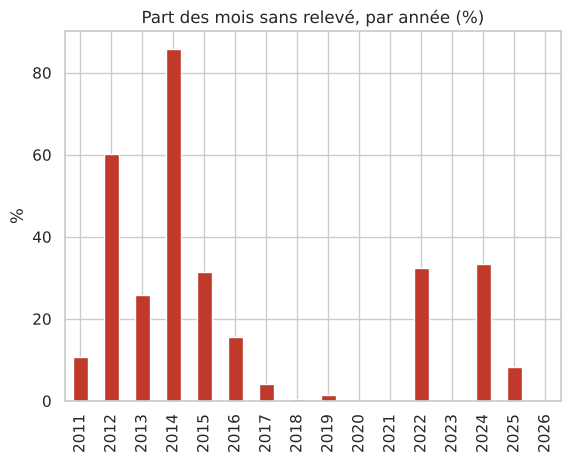

In [22]:
manq = complet.assign(manquant=complet["price"].isna()).groupby(complet["date"].dt.year)["manquant"].mean() * 100
manq.plot(kind="bar", color="#c0392b")
plt.title("Part des mois sans relevé, par année (%)")
plt.ylabel("%")
plt.xlabel("")
plt.show()

#### Observation
Plus de **80 %** de mois manquants en 2014, environ 60 % en 2012, environ 30 % en 2015, 2022 et 2024 ; presque aucun de 2017 à 2021.

#### Analyse
Les trous sont concentrés sur certaines périodes : ils correspondent aux interruptions de la collecte.

#### Interprétation
On ne peut pas traiter tous les trous de la même façon : un trou court peut être estimé, un trou long non.

### Traitement des valeurs manquantes
- Chaque trou est comblé par **interpolation** (ligne droite entre le prix d'avant et celui d'après), sur **3 mois maximum** : un prix ne change pas brutalement en si peu de temps.
- Au-delà, inventer des prix serait malhonnête : les mois restants sont **supprimés**.
- On remet ensuite le département, le GPS et l'unité de chaque série.

In [23]:
complet = complet.sort_values(["market", "commodity", "date"])
complet["price"] = (complet.groupby(["market", "commodity"])["price"]
                    .transform(lambda s: s.interpolate(limit=3, limit_area="inside")))

print("Encore manquants (trous longs) :", complet["price"].isna().sum())
complet = complet.dropna(subset=["price"])

df = complet.merge(infos, left_on=["market", "commodity"], right_index=True)
print("Lignes après traitement :", len(df))
print("Valeurs manquantes      :", df.isna().sum().sum())

Encore manquants (trous longs) :

 885
Lignes après traitement : 6857
Valeurs manquantes      : 0


**Résultat :** 443 mois comblés, 885 supprimés. Il reste **6 857 lignes** et **0 valeur manquante**.

## 12. Valeurs aberrantes
### Pourquoi pas la méthode classique de l'écart interquartile (IQR) ?

In [24]:
q1, q3 = df["price"].quantile([0.25, 0.75])
seuil = q3 + 1.5 * (q3 - q1)
aberrants_iqr = df[df["price"] > seuil]
print("Seuil IQR :", round(seuil), "FCFA")
print("Valeurs signalées :", len(aberrants_iqr))
aberrants_iqr["commodity"].value_counts().head()

Seuil IQR : 3004 FCFA
Valeurs signalées : 529


commodity
Fish (smoked)      228
Fish (salted)      116
Meat (beef)        111
Fish (fresh)        64
Oil (vegetable)      3
Name: count, dtype: int64

**Observation :** l'IQR appliqué à tous les prix signale **529 valeurs**, mais ce sont presque toutes des **poissons et de la viande**, des produits normalement chers (voir analyse bivariée).

Cette méthode n'est pas adaptée. On compare plutôt chaque prix à la **médiane de sa propre série** (même marché, même produit) :
- `mediane_serie` : le prix habituel ;
- `ratio` : combien de fois le prix dépasse ce prix habituel.

In [25]:
df["mediane_serie"] = df.groupby(["market", "commodity"])["price"].transform("median")
df["ratio"] = df["price"] / df["mediane_serie"]

df.sort_values("ratio", ascending=False)[["date", "market", "commodity", "price", "mediane_serie", "ratio"]].head(8)

,date,market,commodity,price,mediane_serie,ratio
2533,2023-06-01,Grand marché/Fond Ntié-Ntié/Nkouikou,Oil (vegetable),23542.0,900.0,26.157778
600,2023-06-01,Betou Centre,Beans (white),13031.0,1491.0,8.739772
189,2016-06-01,Bakandi,Cassava flour,2194.0,407.0,5.390663
2318,2016-03-01,Grand marché/Fond Ntié-Ntié/Nkouikou,"Meat (chicken, frozen)",4416.0,880.0,5.018182
188,2016-05-01,Bakandi,Cassava flour,2000.0,407.0,4.914005
2113,2015-11-01,Grand marché/Fond Ntié-Ntié/Nkouikou,Fish (smoked),13800.0,3119.0,4.424495
2108,2015-06-01,Grand marché/Fond Ntié-Ntié/Nkouikou,Fish (smoked),13000.0,3119.0,4.168003
2107,2015-05-01,Grand marché/Fond Ntié-Ntié/Nkouikou,Fish (smoked),12560.0,3119.0,4.026932


**Observations :**
- L'huile végétale à Pointe-Noire coûte **23 542 FCFA** en juin 2023, soit **26 fois** son prix habituel, alors qu'elle était à 1 350 FCFA en mai et 2 234 en juillet.
- Les haricots à Bétou (ratio 8,7) sont dans le même cas.
- Le poisson fumé à Pointe-Noire reste à environ **4 fois** sa médiane **plusieurs mois de suite** en 2015 : une erreur ne se répète pas ainsi, c'est une **vraie flambée**.

### Visualisation du cas le plus extrême

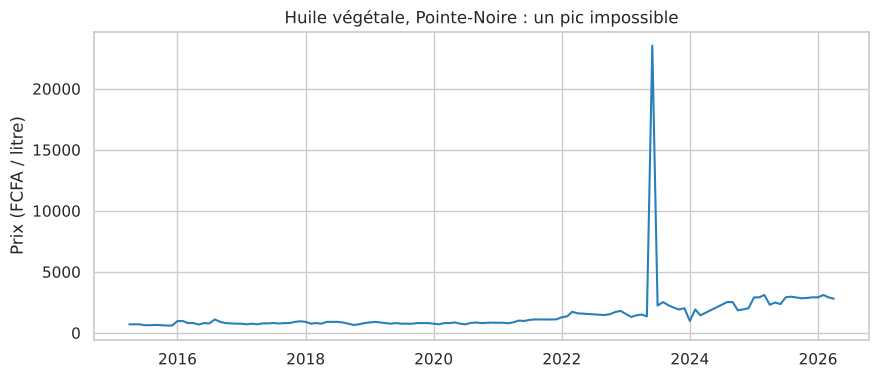

In [26]:
huile = df[(df["commodity"] == "Oil (vegetable)") & (df["market"].str.startswith("Grand"))]
plt.figure(figsize=(10, 4))
plt.plot(huile["date"], huile["price"], color="#2980b9")
plt.title("Huile végétale, Pointe-Noire : un pic impossible")
plt.ylabel("Prix (FCFA / litre)")
plt.show()

#### Observation
Le pic de juin 2023 est **isolé** : le prix revient immédiatement à son niveau le mois suivant.

#### Analyse
Une vraie crise durerait plusieurs mois. On remarque d'ailleurs une vraie hausse progressive à partir de 2022 (d'environ 1 000 à près de 3 000 FCFA en 2026).

#### Interprétation
Le pic est une **erreur de saisie** (peut-être 2 354 avec une virgule oubliée) ; la hausse progressive est réelle et doit être gardée.

### Suppression des erreurs de saisie
On supprime les prix **plus de 5 fois** au-dessus de leur médiane. Le seuil est volontairement large pour ne retirer que les erreurs évidentes et garder les vraies hausses (poisson fumé de 2015).

In [27]:
erreurs = df[df["ratio"] > 5]
print("Erreurs de saisie supprimées :", len(erreurs))
print(erreurs[["date", "market", "commodity", "price", "mediane_serie"]])

df = df[df["ratio"] <= 5].drop(columns=["mediane_serie", "ratio"])
print("Lignes restantes :", len(df))

Erreurs de saisie supprimées : 4
           date                                market               commodity  \
189  2016-06-01                               Bakandi           Cassava flour   
600  2023-06-01                          Betou Centre           Beans (white)   
2318 2016-03-01  Grand marché/Fond Ntié-Ntié/Nkouikou  Meat (chicken, frozen)   
2533 2023-06-01  Grand marché/Fond Ntié-Ntié/Nkouikou         Oil (vegetable)   

        price  mediane_serie  
189    2194.0          407.0  
600   13031.0         1491.0  
2318   4416.0          880.0  
2533  23542.0          900.0  
Lignes restantes : 6853


**Résultat :** 4 erreurs supprimées. Il reste **6 853 lignes**. Le nettoyage est terminé.

## 13. Encodage des variables texte
Un modèle ne comprend que des nombres :
- la **date** devient deux nombres : l'année et le mois ;
- le **département**, le **produit** et l'**unité** passent en **one-hot encoding** (une colonne 0/1 par valeur). On ne les numérote pas (1, 2, 3…), sinon le modèle croirait qu'il existe un ordre entre eux ;
- `market` et `admin2` sont retirés : le département et le GPS décrivent déjà le lieu ;
- `drop_first=True` retire une colonne par variable, car elle se devine à partir des autres.

In [28]:
df["annee"] = df["date"].dt.year
df["mois"] = df["date"].dt.month

df = df.drop(columns=["market", "admin2"])
df = pd.get_dummies(df, columns=["admin1", "commodity", "unit"], drop_first=True, dtype=int)
print("Dimensions :", df.shape)
df.head()

Dimensions : (6853, 31)


,date,price,latitude,longitude,annee,mois,admin1_Brazzaville,admin1_Cuvette,admin1_Lekoumou,admin1_Likouala,...,commodity_Maize flour,commodity_Meat (beef),"commodity_Meat (chicken, frozen)",commodity_Oil (palm),commodity_Oil (vegetable),commodity_Plantains,"commodity_Rice (mixed, low quality)",commodity_Salt,commodity_Wheat flour,unit_L
0,2011-02-01,1500.0,1.64,18.07,2011,2,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,2011-03-01,2000.0,1.64,18.07,2011,3,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,2011-04-01,2000.0,1.64,18.07,2011,4,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2011-05-01,1000.0,1.64,18.07,2011,5,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,2011-06-01,1500.0,1.64,18.07,2011,6,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


**Résultat :** 31 colonnes, toutes numériques (sauf `date`, gardée pour la séparation) : 6 de base, 6 départements, 18 produits, 1 unité.

## 14. Séparation train / test et standardisation
Ce sont des données **dans le temps** : on entraîne sur le passé et on teste sur le futur.
- **Train** : 2011 à 2021
- **Test** : 2022 à 2026

In [29]:
from sklearn.preprocessing import StandardScaler

train = df[df["date"] < "2022-01-01"]
test = df[df["date"] >= "2022-01-01"]

X_train, y_train = train.drop(columns=["date", "price"]), train["price"]
X_test, y_test = test.drop(columns=["date", "price"]), test["price"]

print("Train :", X_train.shape, f"({len(train) / len(df):.0%})")
print("Test  :", X_test.shape, f"({len(test) / len(df):.0%})")

Train : (6134, 29) (90%)
Test  : (719, 29) (10%)


**Résultat :** 6 134 lignes d'entraînement (90 %) et 719 de test (10 %), avec 29 variables explicatives. Le jeu de test est petit car peu de marchés sont suivis après 2021 (voir étape 5).

### Standardisation des variables numériques
On met la latitude, la longitude, l'année et le mois à la même échelle (moyenne 0, écart-type 1), pour qu'aucune ne domine à cause de la taille de ses nombres (2026 contre 12).
Le scaler **apprend** sur le train (`fit_transform`) puis **applique** au test (`transform`), sinon des informations du futur « fuiraient » dans l'entraînement.

In [30]:
colonnes_num = ["latitude", "longitude", "annee", "mois"]

scaler = StandardScaler()
X_train[colonnes_num] = scaler.fit_transform(X_train[colonnes_num])
X_test[colonnes_num] = scaler.transform(X_test[colonnes_num])

X_train[colonnes_num].describe().round(2)

,latitude,longitude,annee,mois
count,6134.00,6134.00,6134.00,6134.00
mean,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00
min,-0.70,-1.47,-2.14,-1.56
25%,-0.52,-0.79,-0.61,-0.98
50%,-0.52,0.14,0.16,-0.09
75%,-0.32,0.14,0.83,0.79
max,2.12,1.70,1.69,1.67


**Vérification :** sur le train, chaque variable a bien une moyenne de 0 et un écart-type de 1 (−0.00 est un arrondi de 0).

# CONCLUSION DU PRÉ-TRAITEMENT

### Ce que l'exploration a montré
- Le prix dépend surtout du **produit**, puis du **lieu** et de la **date**.
- Les données sont **asymétriques**, avec des **valeurs extrêmes**, une collecte **irrégulière** et des variables **déséquilibrées**.

### Ce que le pré-traitement a corrigé
| Problème | Avant | Après |
|---|---|---|
| Colonnes inutiles ou dangereuses | 7 | 0 |
| Faute « Point-Noire » | présente | corrigée |
| Mois manquants cachés | 1 328 | 0 (443 comblés, 885 supprimés) |
| Erreurs de saisie | 4 | 0 |
| Colonnes en texte | 10 | 0 |

**Résultat :** 6 853 lignes propres et 29 variables numériques, prêtes pour la modélisation.



# PARTIE 3 – MODÉLISATION

## 15. Rappel des données prêtes pour la modélisation
- `X` : les **29 variables explicatives** (lieu, date, produit, unité).
- `y` : la **cible**, le prix en FCFA.

In [31]:
# Dimensions des 4 tableaux issus de l'étape 14
print("X_train :", X_train.shape, "  y_train :", y_train.shape)   # passé : 2011 à 2021
print("X_test  :", X_test.shape, "   y_test  :", y_test.shape)    # futur : 2022 à 2026

X_train : (6134, 29)   y_train : (6134,)
X_test  : (719, 29)    y_test  : (719,)


**Résultat :** le train contient **6 134 lignes** et le test **719 lignes**, avec les mêmes **29 variables**. `y_train` et `y_test` contiennent un prix par ligne.

### Quels produits sont dans le train et dans le test ?
Les produits ont été transformés en colonnes 0/1 à l'étape 13. On écrit une petite fonction qui retrouve le nom du produit de chaque ligne, puis on compte les relevés par produit.

In [32]:
colonnes_produits = [c for c in X_test.columns if c.startswith("commodity_")]   # les 18 colonnes 0/1 des produits
tous_les_produits = sorted(infos.index.get_level_values("commodity").unique())   # les 19 produits (étape 11)
produit_reference = tous_les_produits[0]   # produit retiré par drop_first=True (le 1er par ordre alphabétique)
print("Produit de référence (toutes les colonnes produit à 0) :", produit_reference)

def nom_du_produit(ligne):
    """Renvoie le nom du produit d'une ligne à partir de ses colonnes 0/1."""
    if ligne.sum() == 0:                               # aucune colonne à 1 -> c'est le produit de référence
        return produit_reference
    return ligne.idxmax().replace("commodity_", "")    # sinon, la colonne qui vaut 1

produits_train = X_train[colonnes_produits].apply(nom_du_produit, axis=1)   # nom du produit de chaque ligne du train
produits_test = X_test[colonnes_produits].apply(nom_du_produit, axis=1)     # nom du produit de chaque ligne du test

composition = pd.DataFrame({"nb_lignes_train": produits_train.value_counts(),   # relevés par produit (train)
                            "nb_lignes_test": produits_test.value_counts()})    # relevés par produit (test)
composition = composition.fillna(0).astype(int).sort_values("nb_lignes_test", ascending=False)
composition

Produit de référence (toutes les colonnes produit à 0) : Beans (white)


,nb_lignes_train,nb_lignes_test
Cassava flour,571,150
"Rice (mixed, low quality)",676,150
Beans (white),654,149
Oil (vegetable),483,149
Salt,0,121
Cassava (fresh),498,0
Bread,346,0
Fish (smoked),366,0
Cassava meal (foufou),12,0
Fish (fresh),346,0


#### Observation
- Le test ne contient que **5 produits sur 19** : farine de manioc (150), riz (150), haricots (149), huile végétale (149) et sel (121).
- Le **sel** a **0 ligne dans le train** : il n'est relevé qu'à partir de 2022.
- 14 produits du train (poissons, viandes, pain…) sont **absents** du test.
- Le produit de référence (toutes les colonnes produit à 0) est le **haricot** (`Beans (white)`).

#### Analyse
- La colonne `commodity_Salt` vaut toujours 0 dans le train : le modèle n'a jamais appris l'effet du sel.
- Une ligne de sel a donc toutes ses colonnes « connues » à 0, exactement comme un haricot : le modèle la prendra pour un haricot.

#### Interprétation
Le test est petit et très différent du train. On peut s'attendre à de **grosses erreurs sur le sel**, quel que soit le modèle.

## 16. Les 3 métriques d'évaluation
Pour chaque modèle, on compare les **prix devinés** $\hat{y}_i$ aux **vrais prix** $y_i$ du jeu de test ($n$ = 719 lignes).

| Métrique | Formule | Ce qu'elle dit | Meilleure valeur |
|---|---|---|---|
| **MAE** | $\frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$ | l'erreur moyenne, en FCFA | la plus **petite** |
| **MSE** | $\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$ | l'erreur moyenne au carré : punit fort les grosses erreurs | la plus **petite** |
| **R²** | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ | la part des variations du prix expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne $\bar{y}$) | la plus **proche de 1** |

On écrit une petite fonction pour calculer les trois d'un coup.

In [33]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def evaluer(nom_modele, y_reel, y_predit):
    """Calcule R², MSE et MAE, les affiche et les renvoie dans un dictionnaire."""
    r2 = r2_score(y_reel, y_predit)              # R² : proche de 1 = bon
    mse = mean_squared_error(y_reel, y_predit)   # MSE : en FCFA², petit = bon
    mae = mean_absolute_error(y_reel, y_predit)  # MAE : en FCFA, petit = bon
    print(f"{nom_modele} -> R² = {r2:.3f} | MSE = {mse:,.0f} | MAE = {mae:,.0f} FCFA")
    return {"Modèle": nom_modele, "R²": r2, "MSE": mse, "MAE": mae}

resultats = []   # liste qui recevra les scores des 3 modèles

## 17. Modèle 1 : régression linéaire
Le modèle cherche une **équation** de la forme : prix = $b_0 + b_1 \times x_1 + b_2 \times x_2 + \dots$
Chaque variable reçoit un **coefficient** $b_j$, appris sur le train.

In [34]:
from sklearn.linear_model import LinearRegression

modele_lineaire = LinearRegression()                  # création du modèle
modele_lineaire.fit(X_train, y_train)                 # entraînement sur le passé (2011-2021)
pred_lineaire = modele_lineaire.predict(X_test)       # prédiction des prix 2022-2026
resultats.append(evaluer("Régression linéaire", y_test, pred_lineaire))   # calcul des 3 métriques

Régression linéaire -> R² = -0.053 | MSE = 375,401 | MAE = 415 FCFA


#### Observation
- R² = **−0,053** ; MSE = **375 401** ; MAE = **415 FCFA**.

#### Analyse
- Le R² est **négatif** : sur ce test, le modèle fait légèrement **moins bien** que si l'on prédisait toujours le prix moyen.
- En moyenne, il se trompe de **415 FCFA** par relevé.

#### Interprétation
Le résultat est décevant. Les causes sont étudiées aux étapes 21 à 24 (produit inconnu, hausse de prix non prévue).

## 18. Modèle 2 : Random Forest
Une **forêt** de 100 arbres de décision. Chaque arbre pose des questions successives (« Est-ce du poisson ? », « Est-ce Brazzaville ? ») et donne un prix. La forêt fait la **moyenne** des 100 réponses.
`random_state=42` fixe le hasard : on obtient le même résultat à chaque exécution.

In [35]:
from sklearn.ensemble import RandomForestRegressor

modele_rf = RandomForestRegressor(random_state=42, n_jobs=-1)   # 100 arbres ; n_jobs=-1 utilise tous les processeurs
modele_rf.fit(X_train, y_train)                                  # entraînement
pred_rf = modele_rf.predict(X_test)                              # prédiction sur le test
resultats.append(evaluer("Random Forest", y_test, pred_rf))      # calcul des 3 métriques

Random Forest -> R² = -0.331 | MSE = 474,530 | MAE = 441 FCFA


#### Observation
- R² = **−0,331** ; MSE = **474 530** ; MAE = **441 FCFA**.

#### Analyse
- Le R² est encore plus négatif que celui de la régression linéaire (−0,053).
- La MAE est plus élevée de **26 FCFA** (441 contre 415).

#### Interprétation
Malgré ses 100 arbres, la Random Forest fait **moins bien** que la régression linéaire sur ce test.

## 19. Modèle 3 : XGBoost
Des arbres construits **les uns après les autres** : chaque nouvel arbre corrige les erreurs laissées par les arbres précédents (*boosting*).

In [36]:
from xgboost import XGBRegressor

modele_xgb = XGBRegressor(random_state=42)                  # 100 arbres corrigés successivement (réglages par défaut)
modele_xgb.fit(X_train, y_train)                            # entraînement
pred_xgb = modele_xgb.predict(X_test)                       # prédiction sur le test
resultats.append(evaluer("XGBoost", y_test, pred_xgb))      # calcul des 3 métriques

XGBoost -> R² = -0.311 | MSE = 467,435 | MAE = 441 FCFA


#### Observation
- R² = **−0,311** ; MSE = **467 435** ; MAE = **441 FCFA**.

#### Analyse
- XGBoost fait un peu mieux que la Random Forest sur le R² (−0,311 contre −0,331) et la MSE, avec la même MAE (441 FCFA).
- Il reste moins bon que la régression linéaire sur les 3 métriques.

#### Interprétation
Les deux modèles à arbres obtiennent des résultats très proches, et tous deux inférieurs au modèle le plus simple.

## 20. Tableau comparatif des 3 modèles
Les modèles sont triés du meilleur au moins bon, selon le R².

In [37]:
comparaison = (pd.DataFrame(resultats)                      # liste de dictionnaires -> tableau
               .sort_values("R²", ascending=False)          # tri : meilleur R² en premier
               .reset_index(drop=True))
comparaison.index = comparaison.index + 1                   # classement à partir de 1
comparaison.style.format({"R²": "{:.3f}", "MSE": "{:,.0f}", "MAE": "{:,.0f}"})

,Modèle,R²,MSE,MAE
1,Régression linéaire,-0.053,"375,401",415
2,XGBoost,-0.311,"467,435",441
3,Random Forest,-0.331,"474,530",441


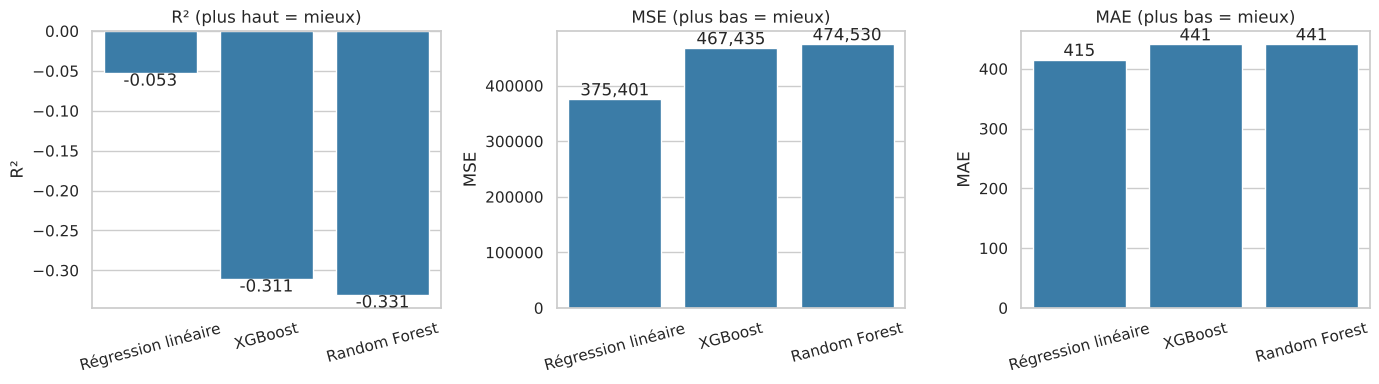

Meilleur modèle : Régression linéaire


In [38]:
# Les 3 métriques côte à côte, en graphique
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metrique in zip(axes, ["R²", "MSE", "MAE"]):
    sns.barplot(data=comparaison, x="Modèle", y=metrique, ax=ax, color="#2980b9")
    ax.set_title(metrique + (" (plus haut = mieux)" if metrique == "R²" else " (plus bas = mieux)"))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    for barre in ax.patches:                                 # valeur écrite au-dessus de chaque barre
        hauteur = barre.get_height()
        texte = f"{hauteur:.3f}" if metrique == "R²" else f"{hauteur:,.0f}"
        position = "bottom" if hauteur >= 0 else "top"       # sous la barre si la valeur est négative
        ax.annotate(texte, (barre.get_x() + barre.get_width() / 2, hauteur), ha="center", va=position)
plt.tight_layout()
plt.show()

meilleur_nom = comparaison.loc[1, "Modèle"]                 # nom du modèle classé 1er
print("Meilleur modèle :", meilleur_nom)

#### Observation
| Rang | Modèle | R² | MSE | MAE (FCFA) |
|---|---|---|---|---|
| 1 | Régression linéaire | −0,053 | 375 401 | 415 |
| 2 | XGBoost | −0,311 | 467 435 | 441 |
| 3 | Random Forest | −0,331 | 474 530 | 441 |

#### Analyse
- La **régression linéaire est 1ʳᵉ sur les 3 métriques** : les métriques sont d'accord entre elles.
- Les **3 R² sont négatifs** : aucun modèle ne fait mieux que le prix moyen sur l'ensemble du test.

#### Interprétation
Le meilleur modèle est la **régression linéaire**, mais il faut comprendre pourquoi tous les scores sont si faibles avant de conclure.

### Score sur le train (déjà vu) vs score sur le test (jamais vu)
Un modèle qui réussit très bien sur le train mais mal sur le test a **appris par cœur** le passé au lieu de comprendre la tendance : c'est le **surapprentissage**.

In [39]:
modeles = {"Régression linéaire": modele_lineaire,      # dictionnaire nom -> modèle entraîné
           "Random Forest": modele_rf,
           "XGBoost": modele_xgb}
train_vs_test = pd.DataFrame({
    "R² train": {nom: r2_score(y_train, m.predict(X_train)) for nom, m in modeles.items()},            # sur le passé
    "R² test": {nom: r2_score(y_test, m.predict(X_test)) for nom, m in modeles.items()},               # sur le futur
    "MAE train": {nom: mean_absolute_error(y_train, m.predict(X_train)) for nom, m in modeles.items()},
    "MAE test": {nom: mean_absolute_error(y_test, m.predict(X_test)) for nom, m in modeles.items()},
})
train_vs_test.style.format({"R² train": "{:.3f}", "R² test": "{:.3f}", "MAE train": "{:,.0f}", "MAE test": "{:,.0f}"})

,R² train,R² test,MAE train,MAE test
Régression linéaire,0.725,-0.053,324,415
Random Forest,0.994,-0.331,42,441
XGBoost,0.975,-0.311,108,441


#### Observation
- Random Forest : R² = **0,994** sur le train, mais **−0,331** sur le test (MAE de 42 → 441 FCFA).
- XGBoost : **0,975** sur le train, **−0,311** sur le test (MAE de 108 → 441 FCFA).
- Régression linéaire : **0,725** sur le train, **−0,053** sur le test (MAE de 324 → 415 FCFA).

#### Analyse
- Les modèles à arbres sont presque **parfaits sur le passé**, mais s'effondrent sur le futur : c'est le signe d'un **surapprentissage**.
- La régression linéaire est moins bonne sur le train, mais **perd beaucoup moins** en passant au test (MAE : +91 FCFA, contre +399 pour la Random Forest).

#### Interprétation
Les arbres ont **appris par cœur** les prix de 2011–2021. Le modèle linéaire, plus simple, **généralise mieux** à des données nouvelles.

## 21. Prix réel vs prix prédit (meilleur modèle)
Chaque point est un relevé du test, coloré selon son produit. S'il tombe sur la **diagonale rouge**, la prédiction est parfaite.

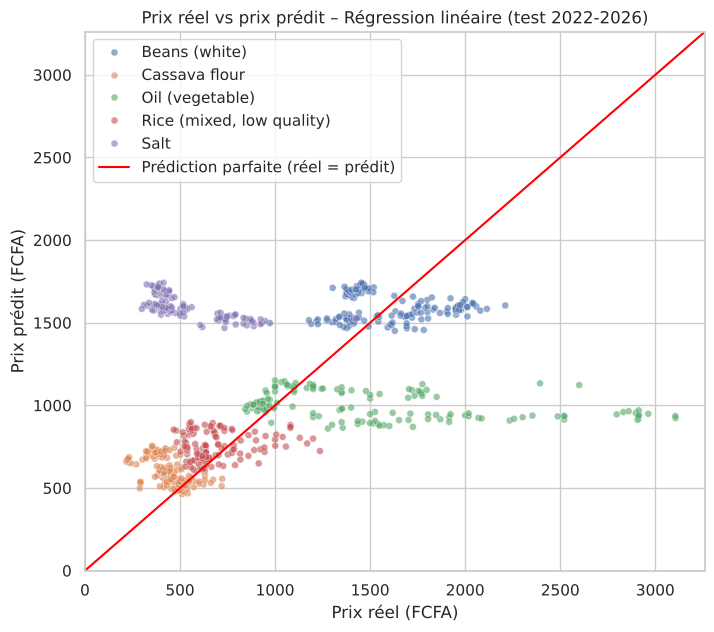

In [40]:
predictions = {"Régression linéaire": pred_lineaire,    # dictionnaire nom -> prédictions
               "Random Forest": pred_rf,
               "XGBoost": pred_xgb}
pred_meilleur = predictions[meilleur_nom]                 # prédictions du meilleur modèle

plt.figure(figsize=(8, 7))
sns.scatterplot(x=y_test.values, y=pred_meilleur,         # un point par relevé du test
                hue=produits_test.values, alpha=0.6, s=25)  # une couleur par produit
borne = max(y_test.max(), pred_meilleur.max()) * 1.05     # limite commune aux deux axes
plt.plot([0, borne], [0, borne], color="red", label="Prédiction parfaite (réel = prédit)")
plt.xlim(0, borne)
plt.ylim(0, borne)
plt.xlabel("Prix réel (FCFA)")
plt.ylabel("Prix prédit (FCFA)")
plt.title(f"Prix réel vs prix prédit – {meilleur_nom} (test 2022-2026)")
plt.legend()
plt.show()

#### Observation
- **Riz** (rouge) et **farine de manioc** (orange) : les points sont proches de la diagonale.
- **Sel** (violet) : les vrais prix vont d'environ 300 à 1 000 FCFA, mais le modèle prédit entre 1 500 et 1 750 FCFA.
- **Huile végétale** (vert) : les vrais prix montent jusqu'à environ 3 100 FCFA, mais les prédictions restent entre 900 et 1 150 FCFA.
- **Haricots** (bleu) : bande presque horizontale, autour de 1 500–1 750 FCFA.

#### Analyse
- Le sel est prédit **au prix d'un haricot** : c'est la confusion annoncée à l'étape 15.
- Pour l'huile, le modèle reproduit les **prix d'avant 2022** et ne voit pas la **hausse** (étape 6 : 1 000 → 1 650 FCFA en 2022, et la hausse progressive notée à l'étape 12).

#### Interprétation
Les grosses erreurs ont **deux causes visibles** : un produit **jamais vu** (le sel) et un **changement de prix** absent du passé (l'huile).

## 22. Les 10 variables les plus importantes
On utilise le meilleur des deux modèles à arbres. L'**importance** mesure à quel point une variable aide les arbres à faire de bonnes prédictions (la somme de toutes les importances vaut 1).

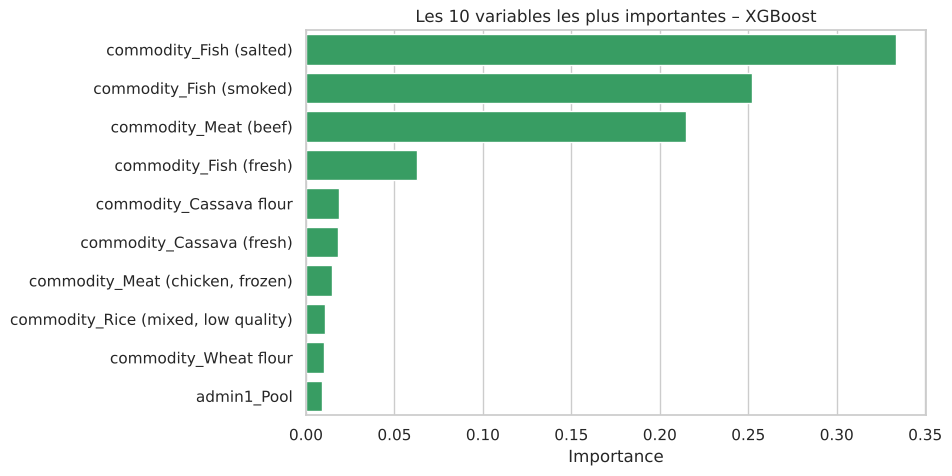

commodity_Fish (salted)                0.334
commodity_Fish (smoked)                0.252
commodity_Meat (beef)                  0.215
commodity_Fish (fresh)                 0.062
commodity_Cassava flour                0.019
commodity_Cassava (fresh)              0.018
commodity_Meat (chicken, frozen)       0.015
commodity_Rice (mixed, low quality)    0.011
commodity_Wheat flour                  0.010
admin1_Pool                            0.009
dtype: float32
Part des 10 premières variables : 95%


In [41]:
# Choix du meilleur modèle à arbres (Random Forest ou XGBoost) d'après le tableau comparatif
modeles_arbres = {"Random Forest": modele_rf, "XGBoost": modele_xgb}
nom_arbre = comparaison[comparaison["Modèle"].isin(modeles_arbres)].iloc[0]["Modèle"]
modele_arbre = modeles_arbres[nom_arbre]

importances = (pd.Series(modele_arbre.feature_importances_, index=X_train.columns)   # une importance par variable
               .sort_values(ascending=False))                                       # de la plus à la moins importante
top10 = importances.head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="#27ae60")
plt.title(f"Les 10 variables les plus importantes – {nom_arbre}")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()

print(top10.round(3))
print("Part des 10 premières variables :", f"{top10.sum():.0%}")

#### Observation
- Les 10 premières variables représentent **95 %** de l'importance totale.
- **9 sur 10 sont des produits**. Les 4 premières : poisson salé (**0,334**), poisson fumé (**0,252**), viande de bœuf (**0,215**), poisson frais (**0,062**), soit **0,863** à elles quatre.
- Une seule variable de lieu : `admin1_Pool` (**0,009**). L'**année** et le **mois** ne sont pas dans le top 10.

#### Analyse
- Le modèle sépare d'abord les **produits chers** (poissons, viande) des produits bon marché.
- Le **temps** compte très peu pour lui.

#### Interprétation
Cela confirme l'exploration (étape 6) : **le produit est le facteur principal** du prix. Comme l'année pèse peu, le modèle ne peut pas suivre une **hausse de prix dans le temps**, ce qui explique l'erreur sur l'huile.

## 23. Erreur moyenne par produit
On calcule la MAE **produit par produit** pour voir où le meilleur modèle se trompe le plus.

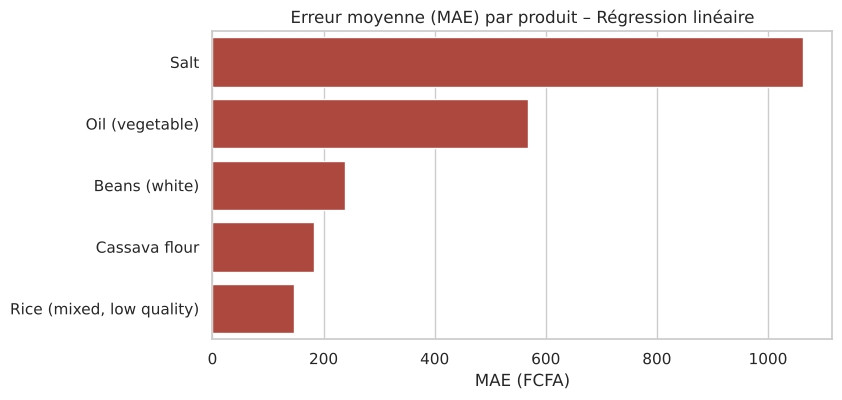

,nb_lignes_train,nb_lignes_test,prix_moyen,MAE,erreur_relative_%
produit,,,,,
Salt,0,121,539.0,1063.0,197.0
Oil (vegetable),483,149,1517.0,568.0,37.0
Beans (white),654,149,1600.0,238.0,15.0
Cassava flour,571,150,441.0,183.0,42.0
"Rice (mixed, low quality)",676,150,679.0,147.0,22.0


In [42]:
erreurs_test = pd.DataFrame({
    "produit": produits_test.values,      # nom du produit de chaque ligne (étape 15)
    "prix_reel": y_test.values,           # vrai prix
    "prix_predit": pred_meilleur,         # prix deviné par le meilleur modèle
})
erreurs_test["erreur_absolue"] = (erreurs_test["prix_reel"] - erreurs_test["prix_predit"]).abs()   # |réel - prédit|

par_produit = (erreurs_test.groupby("produit")
               .agg(nb_lignes_test=("prix_reel", "size"),       # nombre de relevés du produit dans le test
                    prix_moyen=("prix_reel", "mean"),           # prix réel moyen du produit
                    MAE=("erreur_absolue", "mean"))             # erreur moyenne du produit
               .sort_values("MAE", ascending=False))
par_produit["erreur_relative_%"] = par_produit["MAE"] / par_produit["prix_moyen"] * 100   # erreur en % du prix
par_produit["nb_lignes_train"] = composition["nb_lignes_train"]                         # relevés pour apprendre (étape 15)

plt.figure(figsize=(8, 4))
sns.barplot(x=par_produit["MAE"], y=par_produit.index, color="#c0392b")
plt.title(f"Erreur moyenne (MAE) par produit – {meilleur_nom}")
plt.xlabel("MAE (FCFA)")
plt.ylabel("")
plt.show()

par_produit[["nb_lignes_train", "nb_lignes_test", "prix_moyen", "MAE", "erreur_relative_%"]].round(0)

In [43]:
# Erreur moyenne par produit pour les 3 modèles, côte à côte
mae_3_modeles = pd.DataFrame({nom: (y_test - pred).abs().groupby(produits_test).mean()   # MAE de chaque produit
                              for nom, pred in predictions.items()})
mae_3_modeles.round(0)

,Régression linéaire,Random Forest,XGBoost
Beans (white),238.0,336.0,354.0
Cassava flour,183.0,75.0,67.0
Oil (vegetable),568.0,567.0,547.0
"Rice (mixed, low quality)",147.0,170.0,165.0
Salt,1063.0,1207.0,1222.0


#### Observation
- **Sel** : MAE = **1 063 FCFA**, soit **197 %** de son prix moyen (539 FCFA), avec **0 ligne** dans le train.
- **Huile végétale** : MAE = **568 FCFA** (37 % du prix).
- Haricots : 238 FCFA (15 %) ; farine de manioc : 183 FCFA (42 %) ; **riz** : **147 FCFA** (22 %), le mieux prédit.
- Selon les modèles : la régression linéaire est la meilleure sur les haricots (238 contre 336 et 354), le riz et le sel ; les arbres sont bien meilleurs sur la farine de manioc (75 et 67 contre 183) ; sur l'huile, les 3 se trompent autant (547 à 568).

#### Analyse
- Le sel représente 17 % des lignes du test (121 sur 719), mais environ **43 %** de l'erreur totale : 121 × 1 063 ≈ 128 600 FCFA, sur 719 × 415 ≈ 298 400 FCFA.
- Aucun modèle ne réussit sur l'huile : le problème vient des **données** (hausse jamais vue), pas du choix du modèle.

#### Interprétation
Le modèle se trompe le plus là où **il n'a rien pu apprendre** : un produit nouveau (sel) ou un prix qui a changé de niveau (huile).

## 24. Évaluation sur les produits connus du modèle (sans le sel)
Le sel n'a **aucun** relevé dans le train (étape 15) : aucun modèle ne peut apprendre le prix d'un produit qu'il n'a jamais vu.
On recalcule donc les 3 métriques sur les **4 produits connus** (riz, haricots, farine de manioc, huile végétale), pour juger les modèles sur ce qu'ils ont réellement pu apprendre.

In [44]:
produit_inconnu = composition.index[composition["nb_lignes_train"] == 0]   # produits absents du train
masque_connus = ~produits_test.isin(produit_inconnu).values               # True = produit vu pendant l'entraînement
print("Produit(s) jamais vu(s) à l'entraînement :", list(produit_inconnu))
print("Lignes de test gardées :", masque_connus.sum(), "sur", len(y_test))

resultats_connus = [evaluer(nom, y_test[masque_connus], pred[masque_connus])   # 3 métriques sans le sel
                    for nom, pred in predictions.items()]
comparaison_connus = (pd.DataFrame(resultats_connus)
                      .sort_values("R²", ascending=False)                     # meilleur R² en premier
                      .reset_index(drop=True))
comparaison_connus.index = comparaison_connus.index + 1
comparaison_connus.style.format({"R²": "{:.3f}", "MSE": "{:,.0f}", "MAE": "{:,.0f}"})

Produit(s) jamais vu(s) à l'entraînement : ['Salt']
Lignes de test gardées : 598 sur 719
Régression linéaire -> R² = 0.445 | MSE = 208,367 | MAE = 284 FCFA
Random Forest -> R² = 0.394 | MSE = 227,464 | MAE = 286 FCFA
XGBoost -> R² = 0.407 | MSE = 222,677 | MAE = 283 FCFA


,Modèle,R²,MSE,MAE
1,Régression linéaire,0.445,"208,367",284
2,XGBoost,0.407,"222,677",283
3,Random Forest,0.394,"227,464",286


#### Observation
| Rang | Modèle | R² | MSE | MAE (FCFA) |
|---|---|---|---|---|
| 1 | Régression linéaire | 0,445 | 208 367 | 284 |
| 2 | XGBoost | 0,407 | 222 677 | 283 |
| 3 | Random Forest | 0,394 | 227 464 | 286 |

On garde **598 lignes sur 719**.

#### Analyse
- Sans le sel, **les 3 R² deviennent positifs** (de −0,053 à 0,445 pour la régression linéaire) : c'est le sel qui rendait les R² négatifs.
- La MAE est presque identique pour les 3 modèles (283 à 286 FCFA, 3 FCFA d'écart).
- La régression linéaire garde la **meilleure MSE** : elle fait **moins de grosses erreurs** (la MSE punit les grosses erreurs).

#### Interprétation
Sur les produits qu'ils connaissent, les modèles expliquent environ **40 à 45 %** des variations du prix. La **régression linéaire reste la meilleure**, mais de peu.

# CONCLUSION GÉNÉRALE

### 1. Quel modèle gagne ?
La **régression linéaire**.
- Sur tout le test, elle est 1ʳᵉ sur les 3 métriques : R² = −0,053, MSE = 375 401, MAE = 415 FCFA (étape 20).
- Sur les 4 produits connus, elle reste 1ʳᵉ en R² (0,445) et en MSE (208 367), à égalité en MAE (284 FCFA contre 283 pour XGBoost) (étape 24).

### 2. Pourquoi ?
- Les modèles à arbres **apprennent par cœur** le passé : R² de 0,994 (Random Forest) et 0,975 (XGBoost) sur le train, mais négatif sur le test (étape 20).
- La régression linéaire, plus simple, **généralise mieux** : elle perd moins entre le train et le test, et fait moins de grosses erreurs (meilleure MSE).

### 3. Quelles variables comptent le plus ?
Le **produit** : 9 des 10 variables les plus importantes sont des produits. Les poissons et la viande à eux seuls pèsent 0,863 (étape 22). Le lieu compte peu (Pool : 0,009), et la date encore moins (absente du top 10).

### 4. Limites
- **Peu de données après 2021** : 719 lignes de test (10 %), et seulement 5 produits sur 19 (étape 15).
- **Un produit jamais vu** : le sel (0 ligne dans le train) est pris pour un haricot. Il cause environ 43 % de l'erreur totale et rend les R² négatifs (étapes 23 et 24).
- **Un changement de prix non prévu** : l'huile végétale reste prédite autour de 1 000 FCFA alors que son prix monte jusqu'à environ 3 100 FCFA (étape 21).
- **Des produits peu représentés** : foufou (12 lignes de train), farine de maïs (72), plantain (73). Ils sont absents du test : on ne peut donc pas mesurer la qualité des prédictions sur ces produits (étape 15).

### 5. Pistes d'amélioration
- **Ajouter le dataset pluie** (`cog-rainfall-subnat-5ytd.csv`), fusionné par département et par mois : la pluie influence les récoltes, donc les prix, et donnerait au modèle une information qui change dans le temps.
- **Prédire le log du prix** plutôt que le prix : la distribution est très asymétrique (coefficient de 3,7, étape 4). Le log réduit l'écart entre produits bon marché et produits chers.
- **Ajouter le prix du mois précédent** comme variable : le modèle pourrait alors suivre les hausses, comme celle de l'huile.
- **Évaluer à part les produits nouveaux**, comme le sel, ou attendre d'avoir assez de relevés pour les inclure dans le train.